### Symbolic algebra

Symbols, derivatives, functions

*!pip install sympy*

In [2]:
import sympy as smp

t, m, g = smp.symbols('t m g')

In [3]:
t

t

In [4]:
g + m * t**2

g + m*t**2

In [6]:
#r'' for rastering
theta = smp.symbols(r'\theta', cls = smp.Function)
theta = theta(t)

theta

\theta(t)

In [7]:
theta_d = smp.diff(theta, t)

theta_dd = smp.diff(theta, t, t)

In [9]:
theta_d

Derivative(\theta(t), t)

In [10]:
theta_dd

Derivative(\theta(t), (t, 2))

In [11]:
x, y = smp.symbols('x y', cls = smp.Function)

x = x(theta)
y = y(theta)

In [12]:
x

x(\theta(t))

In [13]:
x = smp.sin(theta)
y = smp.cos(theta)

y

cos(\theta(t))

#### Building Lagrangian

In [14]:
T = 1 / 2 * m * (smp.diff(x, t)**2 + smp.diff(y, t)**2)

V = m * g * y

In [15]:
T

0.5*m*(sin(\theta(t))**2*Derivative(\theta(t), t)**2 + cos(\theta(t))**2*Derivative(\theta(t), t)**2)

In [16]:
T = T.simplify()

T

0.5*m*Derivative(\theta(t), t)**2

In [18]:
V

g*m*cos(\theta(t))

In [19]:
L = T - V

In [20]:
L

-g*m*cos(\theta(t)) + 0.5*m*Derivative(\theta(t), t)**2

#### Equations

$\dfrac{d L}{d \theta} - \dfrac{d}{d t}\dfrac{d L}{d \dot{\theta}} = 0$

In [25]:
EL = smp.diff(L, theta) - smp.diff(L, theta_d, t)

In [27]:
EL

g*m*sin(\theta(t)) - 1.0*m*Derivative(\theta(t), (t, 2))

In [28]:
EL.simplify()

m*(g*sin(\theta(t)) - 1.0*Derivative(\theta(t), (t, 2)))

#### Solving for derivatives

In [31]:
deriv_2 = smp.solve(EL, theta_dd)[0]
deriv_1 = theta_d

In [32]:
deriv_2

g*sin(\theta(t))

#### Sanity check: let us obtain Newton's Second Law for point mass on 

- Lagrangian (kinetic energy)
- Euler-Lagrange equation
- Solving for $\ddot{x}$

In [22]:
import numpy as np
import sympy as smp

t, m, F = smp.symbols('t, m, F')
x = smp.symbols('x', cls = smp.Function)

x = x(t)
x_d = smp.diff(x, t)
x_dd = smp.diff(x_d, t)

L = m * x_d**2 / 2

EL1 = - smp.diff(L, x) + smp.diff(L, x_d, t) - F

EL1

-F + m*Derivative(x(t), (t, 2))

In [23]:
x_dd_rhs = smp.solve(EL1, x_dd)[0]

x_dd_rhs

F/m

#### Lambdify

In [55]:
deriv_2f = smp.lambdify((theta, g), deriv_2)
deriv_1f = smp.lambdify((theta_d), deriv_1)

In [61]:
import inspect

params = list(inspect.signature(deriv_2f).parameters.keys())

print(params)

['_Dummy_67', 'g']


In [59]:
deriv_2.atoms(smp.Function)

{\theta(t), sin(\theta(t))}

In [62]:
type(deriv_2f)

function

In [26]:
deriv_2f(1, 2, 3)

np.float64(2.5244129544236893)

In [63]:
deriv_1f(4)

4

#### Let us simulate a system

$\frac{d}{dt}
\begin{pmatrix}
\theta \\
\dot{\theta}
\end{pmatrix}=
$
$\begin{pmatrix}
\dot{\theta} \\
\ddot{\theta}
\end{pmatrix} = f(x, u)
$

In [69]:
import numpy as np
import sympy as smp

t, g, l, m = smp.symbols('t, g, l, m')

#t**2 / g

theta = smp.symbols(r'\theta', cls = smp.Function)

theta = theta(t)
theta_d = smp.diff(theta, t)
theta_dd = smp.diff(theta_d, t)

T = m / 2 * l**2 * theta_d**2

V = m * g * l * smp.cos(theta)

L = T - V

EL1 = smp.diff(L, theta) - smp.diff(L, theta_d, t).simplify()

deriv2 = smp.solve(EL1, theta_dd)

EL1 = EL1.simplify()

EL1

l*m*(g*sin(\theta(t)) - l*Derivative(\theta(t), (t, 2)))

In [70]:
theta_dd_rhs = deriv2[0]

theta_dd_rhs

g*sin(\theta(t))/l

In [71]:
theta_d_f = smp.lambdify((theta_d), theta_d)
theta_dd_f = smp.lambdify((g, theta, l), theta_dd_rhs)

In [73]:
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import numpy as np

#print(theta_dd_f(np.pi**2, 1, 1))

g = 10
l = 1

def xdot(x, t):
    return [
        theta_d_f(x[1]),
        theta_dd_f(g, x[0], l)
    ]

t = np.linspace(0, 10, 1000)

traj = odeint(xdot, y0 = [0.05, -0.03], t = t)

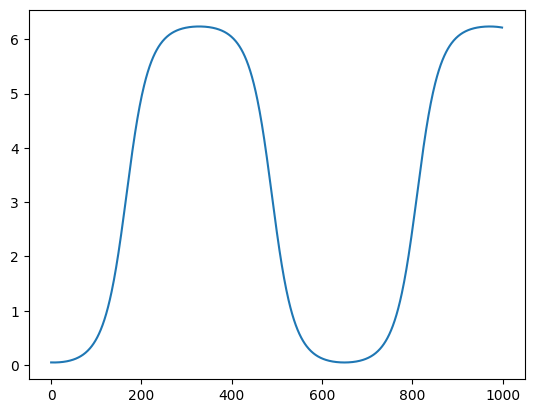

In [75]:
theta_traj = traj.T[0]

#print(theta_traj)

plt.plot(theta_traj)
plt.plot()
plt.show()

#### Let us simulate a double pendulum

In [76]:
import numpy as np
import sympy as smp

t, g, l1, l2, m1, m2 = smp.symbols('t, g, l1, l2, m1, m2')

alpha = smp.symbols(r'\alpha', cls = smp.Function)
alpha = alpha(t)
alpha_d = smp.diff(alpha, t)
alpha_dd = smp.diff(alpha_d, t)

beta = smp.symbols(r'\beta', cls = smp.Function)
beta = beta(t)
beta_d = smp.diff(beta, t)
beta_dd = smp.diff(beta_d, t)

x1 = l1 * smp.sin(alpha)
y1 = l1 * smp.cos(alpha)

x2 = x1 + l2 * smp.sin(alpha + beta)
y2 = y1 + l2 * smp.cos(alpha + beta)

T = m1 / 2 * (smp.diff(x1, t)**2 + smp.diff(y1, t)**2) + \
    m2 / 2 * (smp.diff(x2, t)**2 + smp.diff(y2, t)**2)

V = g * (m1 * y1 + m2 * y2)

L = T - V

EL1 = smp.diff(L, alpha) - smp.diff(L, alpha_d, t).simplify()
EL2 = smp.diff(L, beta) - smp.diff(L, beta_d, t).simplify()

#deriv2 = smp.solve(EL1, theta_dd)

#EL1.simplify()

deriv2 = smp.solve([EL1, EL2], [alpha_dd, beta_dd])

deriv2

{Derivative(\alpha(t), (t, 2)): g*m1*sin(\alpha(t))/(l1*m1 - l1*m2*cos(\beta(t))**2 + l1*m2) - g*m2*sin(\alpha(t) + \beta(t))*cos(\beta(t))/(l1*m1 - l1*m2*cos(\beta(t))**2 + l1*m2) + g*m2*sin(\alpha(t))/(l1*m1 - l1*m2*cos(\beta(t))**2 + l1*m2) + l1*m2*sin(\alpha(t) + \beta(t))*cos(\alpha(t))*cos(\beta(t))*Derivative(\alpha(t), t)**2/(l1*m1 - l1*m2*cos(\beta(t))**2 + l1*m2) + l1*m2*sin(\alpha(t) + \beta(t))*cos(\alpha(t))*cos(\beta(t))*Derivative(\alpha(t), t)*Derivative(\beta(t), t)/(l1*m1 - l1*m2*cos(\beta(t))**2 + l1*m2) - l1*m2*sin(\alpha(t))*cos(\alpha(t) + \beta(t))*cos(\beta(t))*Derivative(\alpha(t), t)**2/(l1*m1 - l1*m2*cos(\beta(t))**2 + l1*m2) - l1*m2*sin(\alpha(t))*cos(\alpha(t) + \beta(t))*cos(\beta(t))*Derivative(\alpha(t), t)*Derivative(\beta(t), t)/(l1*m1 - l1*m2*cos(\beta(t))**2 + l1*m2) - l1*m2*sin(\beta(t))*cos(\beta(t))*Derivative(\alpha(t), t)*Derivative(\beta(t), t)/(l1*m1 - l1*m2*cos(\beta(t))**2 + l1*m2) + l2*m2*sin(\alpha(t) + \beta(t))*cos(\alpha(t))*Derivative(

In [77]:
alpha_dd_rhs = deriv2[alpha_dd].simplify()

alpha_dd_rhs

(2*g*m1*sin(\alpha(t)) - g*m2*sin(\alpha(t) + 2*\beta(t)) + g*m2*sin(\alpha(t)) + l1*m2*sin(2*\beta(t))*Derivative(\alpha(t), t)**2 + 2*l2*m2*sin(\beta(t))*Derivative(\alpha(t), t)**2 + 4*l2*m2*sin(\beta(t))*Derivative(\alpha(t), t)*Derivative(\beta(t), t) + 2*l2*m2*sin(\beta(t))*Derivative(\beta(t), t)**2)/(l1*(2*m1 - m2*cos(2*\beta(t)) + m2))

In [78]:
beta_dd_rhs = deriv2[beta_dd].simplify()

beta_dd_rhs

(-g*l1*m1*sin(\alpha(t) - \beta(t)) + g*l1*m1*sin(\alpha(t) + \beta(t)) - g*l1*m2*sin(\alpha(t) - \beta(t)) + g*l1*m2*sin(\alpha(t) + \beta(t)) - 2*g*l2*m1*sin(\alpha(t)) + g*l2*m2*sin(\alpha(t) + 2*\beta(t)) - g*l2*m2*sin(\alpha(t)) - 2*l1**2*m1*sin(\beta(t))*Derivative(\alpha(t), t)**2 - 2*l1**2*m2*sin(\beta(t))*Derivative(\alpha(t), t)**2 - 2*l1*l2*m2*sin(2*\beta(t))*Derivative(\alpha(t), t)**2 - 2*l1*l2*m2*sin(2*\beta(t))*Derivative(\alpha(t), t)*Derivative(\beta(t), t) - l1*l2*m2*sin(2*\beta(t))*Derivative(\beta(t), t)**2 - 2*l2**2*m2*sin(\beta(t))*Derivative(\alpha(t), t)**2 - 4*l2**2*m2*sin(\beta(t))*Derivative(\alpha(t), t)*Derivative(\beta(t), t) - 2*l2**2*m2*sin(\beta(t))*Derivative(\beta(t), t)**2)/(l1*l2*(2*m1 - m2*cos(2*\beta(t)) + m2))

$\bar{x} = 
\begin{pmatrix}
\alpha \\
\beta \\
\dot{\alpha} \\
\dot{\beta}
\end{pmatrix}
$

In [80]:
alpha_d_f = smp.lambdify((alpha_d), alpha_d)
beta_d_f = smp.lambdify((beta_d), beta_d)

alpha_dd_f = smp.lambdify((g, m1, m2, l1, l2, alpha, beta,
                           alpha_d, beta_d), alpha_dd_rhs)

beta_dd_f = smp.lambdify((g, m1, m2, l1, l2, alpha, beta,
                           alpha_d, beta_d), beta_dd_rhs)

alpha_dd_f(1, 2, 3, 4, 5, 6, 7, 8, 9)

np.float64(244.77893589529805)

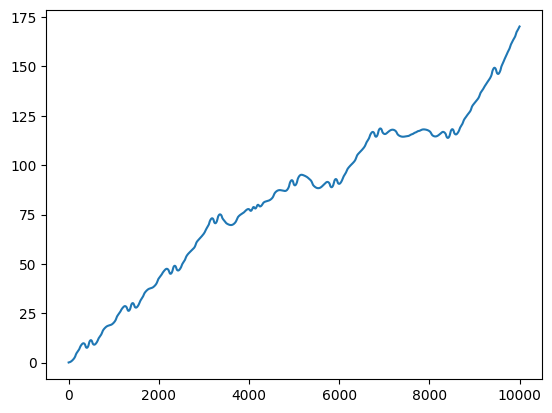

In [84]:
from scipy.integrate import odeint
import matplotlib.pyplot as plt

g = 10
l1 = 0.1
l2 = 1.0
m1 = 1
m2 = 3.1

def xdot(x, t):
    return [
        alpha_d_f(x[2]),
        beta_d_f(x[3]),
        alpha_dd_f(g, m1, m2, l1, l2, x[0], x[1], x[2], x[3]),
        beta_dd_f(g, m1, m2, l1, l2, x[0], x[1], x[2], x[3])
    ]

t = np.linspace(0, 20, 10000)

traj = odeint(xdot, y0 = [0.05, 0.0, 3, -2], t = t)

alpha_traj = traj.T[0]

plt.plot(alpha_traj)
plt.show()

In [ ]:
import numpy as np
import cv2

def polar_to_cartesian(l1, l2, a, b):
    x1 = l1 * np.sin(a)        
    y1 = - l1 * np.cos(a)

    x2 = x1 + l2 * np.sin(a + b)
    y2 = y1 - l2 * np.cos(a + b)
    
    return [[0.0, 0.0], [x1, y1], [x2, y2]]

WIND_X, WIND_Y = 2800, 2200
canvas = np.ones((WIND_Y, WIND_X, 3), np.uint8) * 60

s = 460
i = 0

while (i < len(traj)):
    canvas[:, :, :] = 60
    
    p0, p1, p2 = polar_to_cartesian(l1, l2, traj.T[0, i], traj.T[1, i])
    
    cv2.line(canvas, (int(p0[0] * s + WIND_X // 2), int(p0[1] * s + WIND_Y // 2)),
                     (int(p1[0] * s + WIND_X // 2), int(p1[1] * s + WIND_Y // 2)),
                     (123, 234, 23), 5)

    cv2.line(canvas, (int(p2[0] * s + WIND_X // 2), int(p2[1] * s + WIND_Y // 2)),
                     (int(p1[0] * s + WIND_X // 2), int(p1[1] * s + WIND_Y // 2)),
                     (123, 234, 23), 5)
    
    i += 5
    
    cv2.imshow("canvas", canvas)
    
    key = cv2.waitKey(10)
    
    if (key == ord('q')):
        break

cv2.destroyAllWindows()
cv2.waitKey(50)

-1

: 